## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [ ]:
data = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [ ]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
data.shape

(7043, 21)

In [ ]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
!pip install sweetviz

In [ ]:
import sweetviz as sv

# Generate the EDA report
report = sv.analyze(data)

# Show the report in the notebook
report.show_html("sweetviz_report.html")

                                             |          | [  0%]   00:00 -> (? left)

Report sweetviz_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Data Transformation

In [ ]:
# Dropping unnecessary columns (if applicable)
data.set_index('customerID', inplace=True)

# Converting 'TotalCharges' to numeric
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce').fillna(0).astype(int)

In [ ]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151,Yes


## Label Encoding

In [ ]:
#transfomartion categorical to numerical
from sklearn.preprocessing import LabelEncoder

encode = data[['gender', 'Partner', 'Dependents',
         'PhoneService', 'MultipleLines', 'InternetService',
         'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
         'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
        'PaymentMethod', 'Churn']]

le = LabelEncoder()

for column in encode:
  data[column] = le.fit_transform(data[column])

In [ ]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29,0
5575-GNVDE,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889,0
3668-QPYBK,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108,1
7795-CFOCW,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840,0
9237-HQITU,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151,1


## Correlation Plot

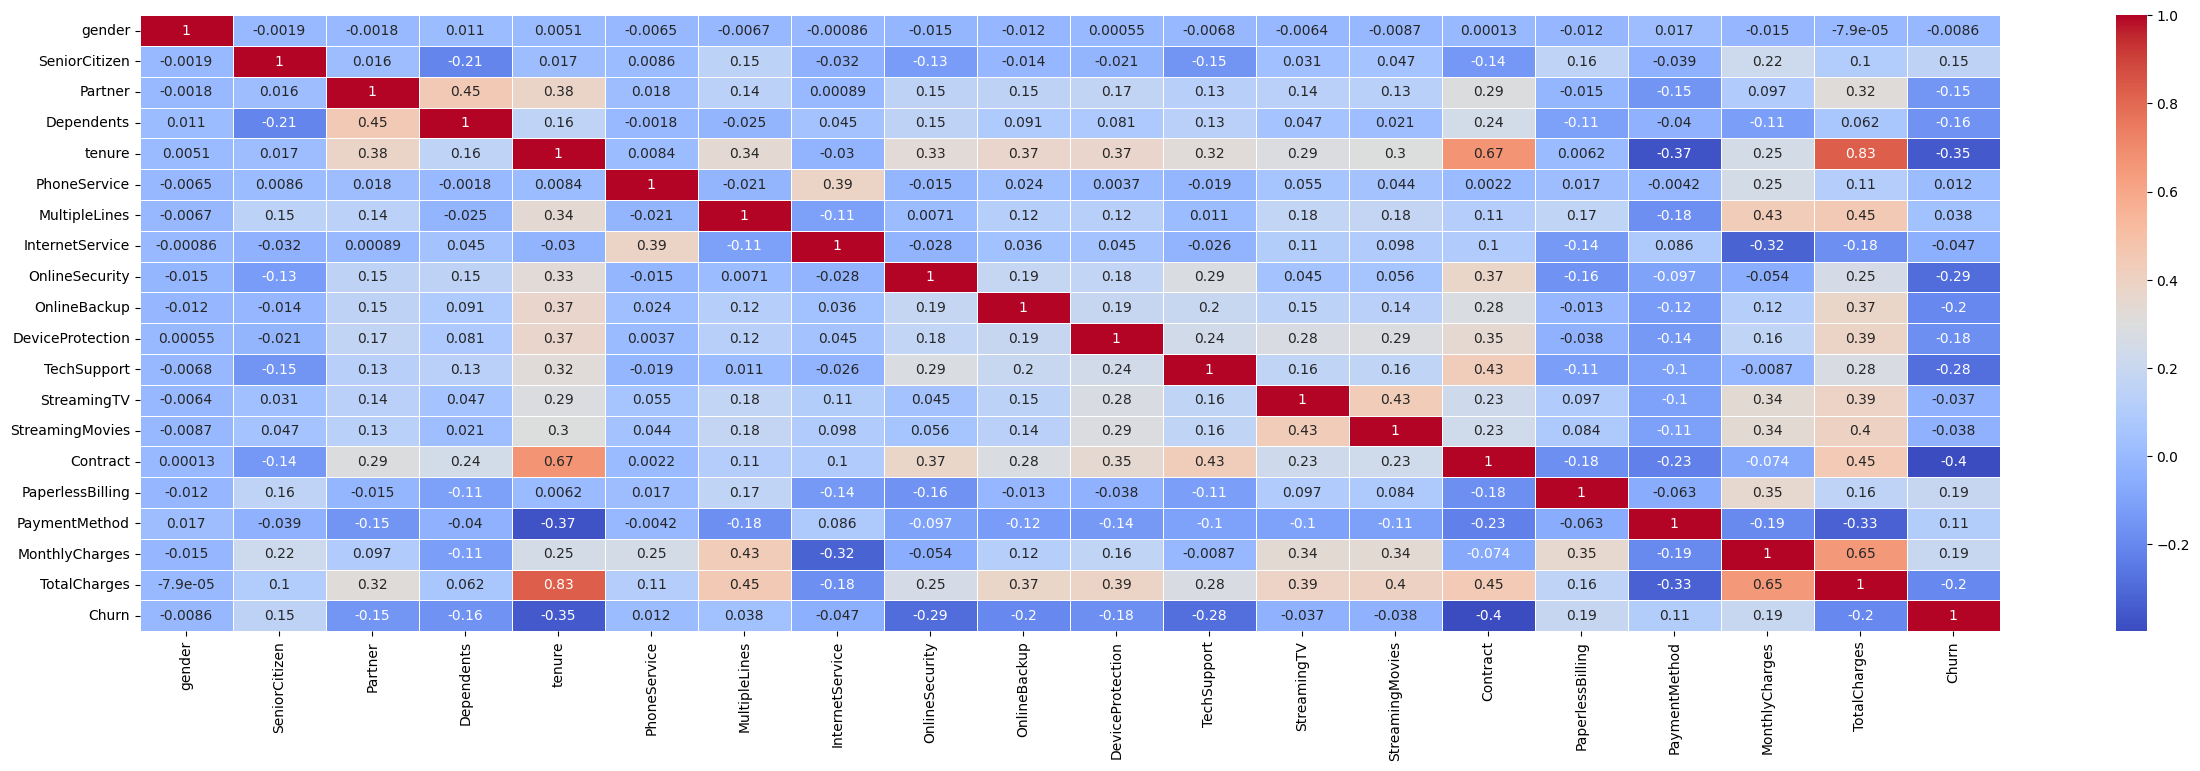

In [ ]:
plt.figure(figsize=(30, 8))
sns.heatmap(data.corr(), annot=True, linewidths=0.5, cmap='coolwarm')
plt.show()

As we can seen figure in above, there are five column that have "positive" correlation on the variable object, that is `Churn`

## Build DT

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
X = data[['PhoneService','MultipleLines','PaperlessBilling','PaymentMethod','MonthlyCharges']]
y = data['Churn']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Train the Decision Tree Classifier
dt = DecisionTreeClassifier(criterion="entropy",random_state=42)
dt.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

## DT Model Evaluation

In [ ]:
# Predict on training and testing data
train_preds = dt.predict(x_train)
test_preds = dt.predict(x_test)

In [ ]:
# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, test_preds)

In [ ]:
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.9359
Testing Accuracy: 0.7012


## Confusion Matrix

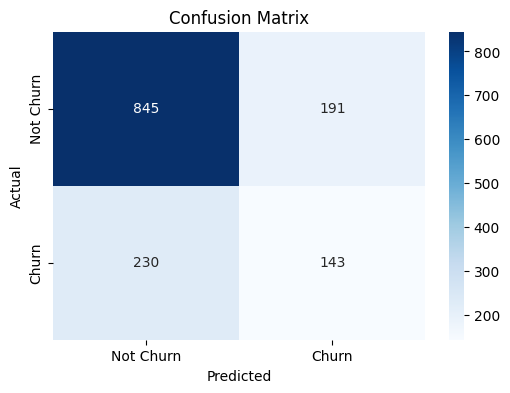

In [ ]:
# confusion metrics

# Compute confusion matrix
cm = confusion_matrix(y_test, test_preds)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not Churn", "Churn"], yticklabels=["Not Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

- True Negative (`TN`): Correctly predicted negative class (Actual = `Not Churn`, Predicted = `Not Churn`)
- False Positive (`FP`): Incorrectly predicted as positive (Actual = `Not Churn`, Predicted = `Churn`)
- False Negative (`FN`): Incorrectly predicted as negative (Actual = `Churn`, Predicted = `Not Churn`)
- True Positive (`TP`): Correctly predicted positive class (Actual = `Churn`, Predicted = `Churn`)

## Classification Report

In [ ]:
# classification report
print("Classification Report (Testing Data):\n")
print(classification_report(y_test, test_preds))

Classification Report (Testing Data):

              precision    recall  f1-score   support

           0       0.79      0.82      0.80      1036
           1       0.43      0.38      0.40       373

    accuracy                           0.70      1409
   macro avg       0.61      0.60      0.60      1409
weighted avg       0.69      0.70      0.70      1409



- The model overfits the training data, as seen by the large gap between training (93.59%) and testing accuracy (70.12%).

- The model performs well on predicting Non-Churn (class 0), but struggles with predicting Churn (class 1), as indicated by the low precision and recall for churn.

- The class imbalance (more Non-Churn instances than Churn) is likely contributing to the model's poor performance on the Churn class.

- Consider using techniques like SMOTE (Synthetic Minority Over-sampling Technique) or class-weight adjustments to handle the class imbalance and explore hyperparameter tuning or regularization to reduce overfitting.

## PLot Decision Tree

In [ ]:
"""from sklearn.tree import plot_tree

# Visualize the decision tree
plt.figure(figsize=(12, 8))
plot_tree(dt, filled=True, feature_names=x_train.columns, class_names=["Not Churn", "Churn"], rounded=True)
plt.title("Decision Tree Visualization")
plt.show()"""

'from sklearn.tree import plot_tree\n\n# Visualize the decision tree\nplt.figure(figsize=(12, 8))\nplot_tree(dt, filled=True, feature_names=x_train.columns, class_names=["Not Churn", "Churn"], rounded=True)\nplt.title("Decision Tree Visualization")\nplt.show()'

In [ ]:
"""from sklearn.tree import plot_tree

# Visualize the decision tree
plt.figure(figsize=(25, 8))
plot_tree(dt, filled=True, feature_names=x_train.columns, max_depth=3, class_names=["Not Churn", "Churn"], rounded=True)
plt.title("Decision Tree Visualization")
plt.show()"""

'from sklearn.tree import plot_tree\n\n# Visualize the decision tree\nplt.figure(figsize=(25, 8))\nplot_tree(dt, filled=True, feature_names=x_train.columns, max_depth=3, class_names=["Not Churn", "Churn"], rounded=True)\nplt.title("Decision Tree Visualization")\nplt.show()'

## Hyperparameter Tuning

In [ ]:
# Train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion="entropy",
                                  random_state=42,
                                  max_depth=10,
                                  min_samples_split=10,
                                  min_samples_leaf=10,
                                  )
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=10,
                       min_samples_split=10, random_state=42)

In [ ]:
# Predict on training and testing data
train_preds = dt_model.predict(x_train)
test_preds = dt_model.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, test_preds)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7703
Testing Accuracy: 0.7324


In [ ]:
# classificaion report
print("Classification Report (Hyperparameter):\n")
print(classification_report(y_test, test_preds))

Classification Report (Hyperparameter):

              precision    recall  f1-score   support

           0       0.79      0.87      0.83      1036
           1       0.49      0.34      0.40       373

    accuracy                           0.73      1409
   macro avg       0.64      0.61      0.62      1409
weighted avg       0.71      0.73      0.72      1409



## Grid Search

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [ ]:
# Train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='entropy',
                                  random_state=42)
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
# hyperparameter grid
param_grid = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_leaf_nodes': [10, 20, 50]
}

In [ ]:
# Initialize GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(estimator=dt_model,
                           param_grid=param_grid,
                           cv=5,
                           scoring='accuracy',
                           n_jobs = -1, # use all cpu cores
                           verbose = 2 # print progress
                           )

In [ ]:
# Fit Grid Search to the training data
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


GridSearchCV(cv=5,
             estimator=DecisionTreeClassifier(criterion='entropy',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10, 15],
                         'max_leaf_nodes': [10, 20, 50],
                         'min_samples_leaf': [1, 5, 10, 20],
                         'min_samples_split': [2, 5, 10, 20]},
             scoring='accuracy', verbose=2)

In [ ]:
# Display the best parameters found by GridSearchCV
print("Best Hyperparameters from Grid Search:", grid_search.best_params_)

Best Hyperparameters from Grid Search: {'max_depth': 15, 'max_leaf_nodes': 50, 'min_samples_leaf': 20, 'min_samples_split': 2}


In [ ]:
# Evaluate the model with the best parameters on the test set
best_dt_model = grid_search.best_estimator_
y_pred = best_dt_model.predict(x_test)

In [ ]:
# Predict on training and testing data
train_preds = best_dt_model.predict(x_train)
test_preds = best_dt_model.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7620
Testing Accuracy: 0.7544


In [ ]:
print("Classification Report (Grid Search):")
print(classification_report(y_test, y_pred))

Classification Report (Grid Search):
              precision    recall  f1-score   support

           0       0.80      0.89      0.84      1036
           1       0.56      0.36      0.44       373

    accuracy                           0.75      1409
   macro avg       0.68      0.63      0.64      1409
weighted avg       0.73      0.75      0.74      1409



In [ ]:
print("Confusion Matrix (Grid Search):")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix (Grid Search):
[[927 109]
 [237 136]]


## Randomized Search

In [ ]:
# hyperparameter distribution
from scipy.stats import randint

param_dist = {
    'max_depth': randint(3, 15),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'max_leaf_nodes': randint(10, 100)
}

In [ ]:
# initialize random search
random_search = RandomizedSearchCV(estimator=dt_model,
                                   param_distributions=param_dist,
                                   n_iter=100,  #number of iterations
                                   cv=5,
                                   scoring='accuracy',
                                   n_jobs=-1,
                                   verbose=2
                                  )

In [ ]:
# Fit Random Search to the training data
random_search.fit(x_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


RandomizedSearchCV(cv=5,
                   estimator=DecisionTreeClassifier(criterion='entropy',
                                                    random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f22ec924220>,
                                        'max_leaf_nodes': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f22ea916cb0>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f22ec9257e0>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f22ea917460>},
                   scoring='accuracy', verbose=2)

In [ ]:
# Display the best parameters found by RandomizedSearchCV
print("Best Hyperparameters from Random Search:", random_search.best_params_)

Best Hyperparameters from Random Search: {'max_depth': 6, 'max_leaf_nodes': 13, 'min_samples_leaf': 8, 'min_samples_split': 11}


In [ ]:
# Evaluate the model with the best parameters on the test set
best_dt_model_random = random_search.best_estimator_
y_pred_random = best_dt_model_random.predict(x_test)

In [ ]:
# Predict on training and testing data
train_preds = best_dt_model_random.predict(x_train)
test_preds = best_dt_model_random.predict(x_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_preds)
test_accuracy = accuracy_score(y_test, y_pred_random)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.7636
Testing Accuracy: 0.7537


In [ ]:
print("Classification Report (Random Search):")
print(classification_report(y_test, y_pred_random))

Classification Report (Random Search):
              precision    recall  f1-score   support

           0       0.79      0.90      0.84      1036
           1       0.56      0.35      0.43       373

    accuracy                           0.75      1409
   macro avg       0.67      0.62      0.63      1409
weighted avg       0.73      0.75      0.73      1409



In [ ]:
print("Confusion Matrix (Random Search):")
print(confusion_matrix(y_test, y_pred_random))

Confusion Matrix (Random Search):
[[933 103]
 [244 129]]


## Summary :

`Accuracy`: We observed that the accuracy steadily improved with hyperparameter tuning methods:
1. Plain DT: 70%
2. Cross Validation Score : 68%
3. Hyperparameter Tuning: 73%
4. Grid Search: 75%
5. Random Search: 76%

`Class 0 (Majority Class)`:

1. **Recall** for Class 0 improves significantly in all tuned models, from 0.82 (plain DT) to 0.89 (Random Search).
2. **Precision** for Class 0 remains fairly consistent across all models (~0.79 - 0.81).

`Class 1 (Minority Class)`:

1. **Precision** for Class 1 improves with hyperparameter tuning: from 0.43 (plain DT) to 0.57 (Random Search), reflecting a better ability to identify minority class instances.
2. **Recall** for Class 1, however, remains low throughout (~0.38 - 0.42), with Grid Search and Random Search providing the best improvements in recall.

Hyperparameter tuning (via Grid Search or Random Search) improves accuracy, precision, and recall, especially for the minority class.

Random Search provides the best results overall, with the highest accuracy, precision, and F1-Score for both classes.

The model still struggles with the minority class (Class 1), but the tuning methods help improve performance in a highly imbalanced dataset.